In [2]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

In [3]:
L = tf.keras.layers

In [4]:
tr = pd.read_csv("sign_mnist_train.csv")
te = pd.read_csv("sign_mnist_test.csv")
Xtr,ytr = tr.drop(columns="label").values.reshape(-1,28,28,1) / 255, tr.label.values
Xte,yte = te.drop(columns="label").values.reshape(-1,28,28,1) / 255, te.label.values

In [5]:
model = tf.keras.Sequential([L.Conv2D(32, 3, activation="relu"), L.MaxPooling2D(), L.Conv2D(64, 3, activation="relu"), L.MaxPooling2D(),
                             L.Flatten(), L.Dense(128, activation="relu"), L.Dense(25, activation="softmax")])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h = model.fit(Xtr, ytr, epochs=10, batch_size=128, validation_data=(Xte, yte))

Epoch 1/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2497 - loss: 2.5938 - val_accuracy: 0.7271 - val_loss: 0.9003
Epoch 2/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8554 - loss: 0.5076 - val_accuracy: 0.8207 - val_loss: 0.5330
Epoch 3/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9690 - loss: 0.1478 - val_accuracy: 0.8597 - val_loss: 0.4439
Epoch 4/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9965 - loss: 0.0444 - val_accuracy: 0.8872 - val_loss: 0.3920
Epoch 5/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9997 - loss: 0.0166 - val_accuracy: 0.8982 - val_loss: 0.3577
Epoch 6/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 1.0000 - loss: 0.0088 - val_accuracy: 0.8981 - val_loss: 0.3639
Epoch 7/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 1.0000 - loss: 0.0049 - val_accuracy: 0.9053 - val_loss: 0.3732
Epoch 8/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 1.0000 - loss: 0.0033 - val_accurac

In [7]:
print(model.evaluate(Xte, yte))                                  
print(classification_report(yte, model.predict(Xte).argmax(1)))  

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8980 - loss: 0.4118
[0.3958401381969452, 0.9040713906288147]
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       331
           1       1.00      0.95      0.98       432
           2       1.00      0.98      0.99       310
           3       1.00      0.90      0.95       245
           4       0.86      0.93      0.90       498
           5       0.93      1.00      0.96       247
           6       0.92      0.93      0.93       348
           7       0.95      0.91      0.93       436
           8       0.93      0.98      0.96       288
          10       0.94      0.79      0.86       331
          11       0.88      1.00      0.93       209
          12       0.94      0.84      0.89       394
          13       0.92      0.86      0.88       291
          14       1.00      0.88      0.94       246
          15       0.96      1.0

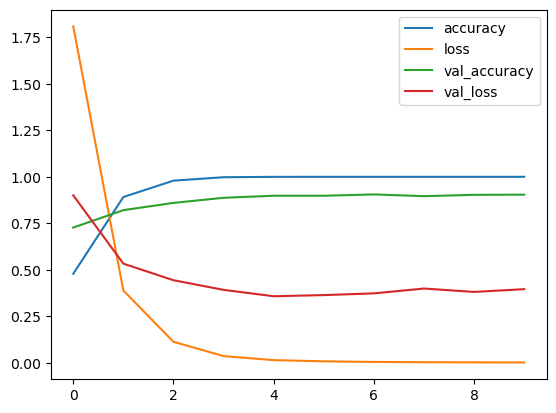

In [8]:
pd.DataFrame(h.history).plot(); 
plt.show()                       

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


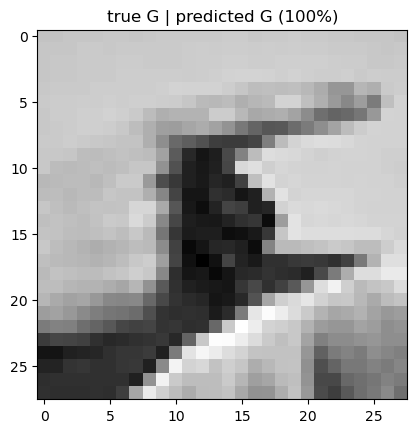

In [9]:
#one example
names = [chr(65+k) for k in range(25)]                         # label 0 = A ... 24 = Y
i = 0                                                          # any test image
p = model.predict(Xte[i:i+1])[0]                               # one probability per class
plt.imshow(Xte[i].squeeze(), cmap="gray"); plt.title(f"true {names[yte[i]]} | predicted {names[p.argmax()]} ({p.max():.0%})")
plt.show()